# Chapter 26: Project: Household Budget

The programs from Chapter 26 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Where the Money Goes

`budget_review.py`

In [1]:
import pandas as pd

budget = pd.read_csv("../data/budget.csv", parse_dates=["date"])
rules = {
    "Income": r"SALARY",
    "Housing": r"RENT|POWER",
    "Groceries": r"FRESHMART",
    "Coffee": r"CAFE",
    "Transport": r"TRANSIT|RIDESHARE",
    "Shopping": r"ONLINE STORE",
    "Subscriptions": r"SUBSCRIPTION",
}
budget["category"] = "Other"
for name, pattern in rules.items():
    budget.loc[budget["description"].str.contains(pattern), "category"] = (
        name
    )

income = budget.loc[budget["amount"] > 0, "amount"].sum()
spending = -budget.loc[budget["amount"] < 0, "amount"].sum()
print(
    f"income ${income:,.2f}, spending ${spending:,.2f}, "
    f"saved {1 - spending / income:.1%}"
)
print()
monthly = (
    budget[budget["amount"] < 0]
    .pivot_table(
        index=budget["date"].dt.month,
        columns="category",
        values="amount",
        aggfunc="sum",
    )
    .mul(-1)
    .fillna(0)
)
print(
    monthly.mean()
    .sort_values(ascending=False)
    .round(2)
    .rename("average per month")
)

income $50,400.00, spending $26,552.35, saved 47.3%

category
Housing          1556.67
Groceries         414.82
Shopping          154.16
Coffee             44.51
Transport          29.55
Subscriptions      12.99
Name: average per month, dtype: float64


## Finding Recurring Payments

`recurring.py`

In [2]:
import pandas as pd

budget = pd.read_csv("../data/budget.csv", parse_dates=["date"])
spend = budget[budget["amount"] < 0]

# A payment is recurring if the same description and amount appear in
# at least 10 different months
by_payment = spend.groupby(["description", "amount"])["date"].agg(
    months=lambda d: d.dt.month.nunique()
)
recurring = by_payment[by_payment["months"] >= 10].reset_index()
recurring["per year"] = -recurring["amount"] * recurring["months"]
print(
    recurring.sort_values("per year", ascending=False).to_string(
        index=False
    )
)

            description   amount  months  per year
     RENT MAPLE HOUSING -1450.00      12  17400.00
STREAMFLIX SUBSCRIPTION   -12.99      12    155.88


## The Chart

`budget_chart.py`

Saved budget_chart.png


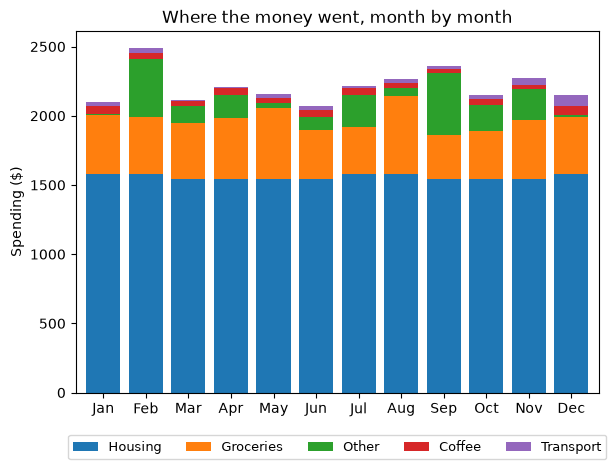

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

budget = pd.read_csv("../data/budget.csv", parse_dates=["date"])
budget = budget[budget["amount"] < 0]
rules = {
    "Housing": r"RENT|POWER",
    "Groceries": r"FRESHMART",
    "Coffee": r"CAFE",
    "Transport": r"TRANSIT|RIDESHARE",
}
budget["category"] = "Other"
for name, pattern in rules.items():
    budget.loc[budget["description"].str.contains(pattern), "category"] = (
        name
    )
monthly = (
    budget.pivot_table(
        index=budget["date"].dt.strftime("%m"),
        columns="category",
        values="amount",
        aggfunc="sum",
    )
    .mul(-1)
    .fillna(0)
)
monthly = monthly[["Housing", "Groceries", "Other", "Coffee", "Transport"]]

fig, ax = plt.subplots()
monthly.plot.bar(stacked=True, ax=ax, width=0.8)
ax.set_xticklabels(
    [
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    ],
    rotation=0,
)
ax.set_xlabel("")
ax.set_ylabel("Spending ($)")
ax.set_title("Where the money went, month by month")
ax.legend(
    ncol=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1)
)
fig.tight_layout()
fig.savefig("budget_chart.png")
print("Saved budget_chart.png")